<a href="https://colab.research.google.com/github/k1-r1ll/pytorch/blob/main/pytorch5_collab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Uploading packages and data

In [2]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import numpy as np
from matplotlib import cm
from tqdm.auto import tqdm
import copy
from IPython.display import clear_output

In [4]:
warnings.filterwarnings("ignore")
%matplotlib inline

import torch
import torchvision

In [5]:
from torch import nn
import torch.nn.functional as F
import torch.optim as optim

In [6]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split

In [7]:
!pip install wget

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=020e7e420cab8c58a5893ad071c15e6c92a3c47f280686e57419590de03adc06
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


In [8]:
import wget

In [9]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [10]:
device

device(type='cuda', index=0)

In [11]:
!wget --no-check-certificate \
    https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip \
    -O /content/cats_and_dogs_filtered.zip

!unzip -q /content/cats_and_dogs_filtered.zip -d ./data/

--2026-10-28 13:43:24--  https://storage.googleapis.com/tensorflow-1-public/course2/cats_and_dogs_filtered.zip
Resolving storage.googleapis.com (storage.googleapis.com)... 34.153.2.27, 104.154.125.27, 34.153.3.27, ...
Connecting to storage.googleapis.com (storage.googleapis.com)|34.153.2.27|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 68606236 (65M) [application/zip]
Saving to: ‘/content/cats_and_dogs_filtered.zip’

/content/cats_and_d 100%[===================>]  65.43M  18.0MB/s    in 5.1s    

2026-10-28 13:43:30 (12.9 MB/s) - ‘/content/cats_and_dogs_filtered.zip’ saved [68606236/68606236]



In [12]:
# 2. Main functions

In [13]:
# Plot function
def plot_losses(train_losses, test_losses, train_accuracies, test_accuracies):
    clear_output()
    fig, axs = plt.subplots(1, 2, figsize=(13, 4))
    axs[0].plot(range(1, len(train_losses) + 1), train_losses, label='train')
    axs[0].plot(range(1, len(test_losses) + 1), test_losses, label='test')
    axs[0].set_ylabel('loss')

    axs[1].plot(range(1, len(train_accuracies) + 1), train_accuracies, label='train')
    axs[1].plot(range(1, len(test_accuracies) + 1), test_accuracies, label='test')
    axs[1].set_ylabel('accuracy')

    for ax in axs:
        ax.set_xlabel('epoch')
        ax.legend()

    plt.show()

In [14]:
# One epoch training functions
def training_epoch(model, optimizer, criterion, train_loader, tqdm_desc, wandb_project=None):
    """Одна эпоха обучения"""
    train_loss, train_accuracy = 0.0, 0.0
    model.train()
    for images, labels in tqdm(train_loader, desc=tqdm_desc):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.shape[0]
        train_accuracy += (logits.argmax(dim=1) == labels).sum().item()

        if wandb_project:
            metrics = {
                "batch-train/loss": loss.item()
            }
            wandb.log(metrics)

    train_loss /= len(train_loader.dataset)
    train_accuracy /= len(train_loader.dataset)
    return train_loss, train_accuracy

In [15]:
# Validation function
@torch.no_grad()
def validation_epoch(model, criterion, val_loader, tqdm_desc):
    """Прогнозы на валидации"""

    val_loss, val_accuracy = 0.0, 0.0
    model.eval()
    for images, labels in tqdm(val_loader, desc=tqdm_desc):
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        val_loss += loss.item() * images.shape[0]
        val_accuracy += (logits.argmax(dim=1) == labels).sum().item()

    val_loss /= len(val_loader.dataset)
    val_accuracy /= len(val_loader.dataset)
    return val_loss, val_accuracy

In [16]:
# Train function
def train(model, optimizer, criterion, train_loader, val_loader, num_epochs, scheduler=None, wandb_project=None):
    """Обучение модели"""
    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    if wandb_project:
        wandb.init(project=wandb_project)
        wandb.watch(model)

    for epoch in range(1, num_epochs + 1):
        train_loss, train_accuracy = training_epoch(
            model, optimizer, criterion, train_loader,
            tqdm_desc=f'Training {epoch}/{num_epochs}',
            wandb_project=wandb_project
        )
        val_loss, val_accuracy = validation_epoch(
            model, criterion, val_loader,
            tqdm_desc=f'Validating {epoch}/{num_epochs}'
        )

        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        if scheduler is not None:
            scheduler.step()

        if wandb_project:
            metrics = {
                "train/loss": train_loss / len(train_loader.dataset),
                "train/accuracy": train_accuracy / len(train_loader.dataset),
                "val/loss": val_loss,
                "val/accuracy": val_accuracy
            }
            wandb.log(metrics)
        else:
          plot_losses(train_losses, val_losses, train_accuracies, val_accuracies)

    print(f"Epoch: {epoch}, loss: {np.mean(val_loss)}, accuracy: {np.mean(val_accuracy)}")

In [17]:
# 3. Data preparation

In [18]:
# 3.1. Basic data preparation

In [19]:
normalize = T.Normalize(mean=[0.4914, 0.4822, 0.4465],
            std=[0.247, 0.243, 0.261])

# Это из лекции
train_transform = T.Compose([
    T.RandomResizedCrop(224),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    normalize
])

test_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    normalize
])

# Это сделал с ИИ, поменял размер картинок, чтобы попробовать полносвязную сеть
# train_transform = T.Compose([
#     T.RandomResizedCrop(64), # Было 224
#     T.RandomHorizontalFlip(),
#     T.ToTensor(),
#     normalize
# ])

# test_transform = T.Compose([
#     T.Resize(72),             # Было 256 (пропорционально уменьшаем)
#     T.CenterCrop(64),         # Было 224
#     T.ToTensor(),
#     normalize
# ])

train_full = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = train_transform
)

val_full = ImageFolder(
    "data/cats_and_dogs_filtered/train",
    transform = train_transform
    #transform = test_transform
)

generator = torch.Generator().manual_seed(42)

train_idx, val_idx = torch.utils.data.random_split(
    range(len(train_full)),
    [int(0.8 * len(train_full)), len(train_full) - int(0.8 * len(train_full))],
    generator=generator
)

train_dataset = torch.utils.data.Subset(
    train_full, train_idx.indices
)
val_dataset = torch.utils.data.Subset(
    val_full, val_idx.indices
)

test_dataset = ImageFolder(
    "data/cats_and_dogs_filtered/validation",
    transform = test_transform
)

In [20]:
x = !ls data/cats_and_dogs_filtered/train/cats
y = !ls data/cats_and_dogs_filtered/train/dogs
len(x), len(y)

(167, 167)

In [21]:
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size     = 32,
    shuffle        = True,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

val_loader = torch.utils.data.DataLoader(
    val_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size     = 4096,
    shuffle        = False,
    pin_memory=device.type == "cuda",
    num_workers    = 2
)

In [ ]:
# 3.2. Data preparation with augmentation

In [ ]:
# --- 1. СТАНДАРТНАЯ НОРМАЛИЗАЦИЯ ---
# Приводит значения пикселей к единому распределению.
# Эти значения mean и std — стандартные для сетей, предобученных на ImageNet.
normalize = T.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

# --- 2. ТРАНСФОРМАЦИЯ С АУГМЕНТАЦИЕЙ (ДЛЯ ОБУЧЕНИЯ) ---
# Искусственно создает разнообразие картинок, чтобы сеть не зазубривала их.
aug_transform = T.Compose([
    # Случайно вырезает кусок картинки (от 70% до 100% площади) и растягивает до 224x224
    T.RandomResizedCrop(224, scale=(0.7, 1.0)),
    # Случайно отражает картинку по горизонтали (слева направо) с вероятностью 50%
    T.RandomHorizontalFlip(),
    # Случайно меняет яркость, контраст и насыщенность на +-20%
    T.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
    ),
    # Переводит картинку из формата PIL Image в тензор PyTorch (значения от 0 до 1)
    T.ToTensor(),
    # Применяет нормализацию, созданную выше
    normalize,
])

# --- 3. БАЗОВАЯ ТРАНСФОРМАЦИЯ (ДЛЯ ВАЛИДАЦИИ / ТЕСТА) ---
# Никаких случайных искажений! Картинка должна быть обработана «честно».
base_transform = T.Compose([
    # Сначала сжимает меньшую сторону картинки до 256 пикселей
    T.Resize(256),
    # Вырезает идеальный квадрат 224x224 строго по центру
    T.CenterCrop(224),
    # Переводит в тензор и нормализует
    T.ToTensor(),
    normalize,
])

# --- 4. ЗАГРУЗКА ДАТАСЕТОВ ИЗ ПАПОК ---
# ImageFolder автоматически разбивает картинки на классы по названиям подпапок

# Тренировочный датасет БЕЗ аугментации (оригинальные картинки)
train_full = ImageFolder(
    root="data/cats_and_dogs_filtered/train",
    transform=base_transform,
)

# Тренировочный датасет С АУГМЕНТАЦИЕЙ (искаженные картинки для лучшего обобщения)
train_full_aug = ImageFolder(
    root="data/cats_and_dogs_filtered/train",
    transform=aug_transform,
)

# Валидационный датасет (для проверки качества модели во время обучения)
# Примечание: в самом низу кода опечатка/копипаст автора, там путь тоже ведет на /train,
# хотя для валидации правильнее использовать путь с /validation или /val в конце.
val_full = ImageFolder(
    root="data/cats_and_dogs_filtered/train", # <-- тут скорее всего должен быть /val
    transform=base_transform,
)

generator = torch.Generator().manual_seed(42)
train_idx, val_idx = torch.utils.data.random_split(
    range(len(train_full)),
    [int(0.8 * len(train_full)), len(train_full) - int(0.8 * len(train_full))],
    generator=generator
)

train_dataset = torch.utils.data.Subset(
    train_full, train_idx.indices
)
val_dataset = torch.utils.data.Subset(
    val_full, val_idx.indices
)

test_dataset = ImageFolder(
    "data/cats_and_dogs_filtered/validation",
    transform = base_transform
)

In [ ]:
# --- 1. ЛОАДЕР ДЛЯ СТАНДАРТНОГО ОБУЧЕНИЯ ---
train_loader = DataLoader(
    train_dataset,                # Исходный тренировочный датасет без аугментаций
    batch_size=32,                # Модель будет брать по 32 картинки за раз
    shuffle=True,                 # Перемешиваем картинки каждую эпоху, чтобы сеть не привыкала к порядку
    pin_memory=device.type == "cuda", # Ускоряет перенос данных из оперативной памяти в видеокарту (если учим на GPU)
    num_workers=0,                # Сколько доп. процессов процессора грузят данные (0 означает загрузку в основном потоке)
)

# --- 2. ЛОАДЕР ДЛЯ ОБУЧЕНИЯ С АУГМЕНТАЦИЕЙ ---
train_loader_aug = DataLoader(
    train_full_aug,               # Исходный датасет со случайными искажениями (повороты, цвет и т.д.)
    batch_size=32,                # Размер пачки тоже 32
    shuffle=True,                 # Обязательно перемешиваем
    pin_memory=device.type == "cuda",
    num_workers=0,
)

# --- 3. ЛОАДЕР ДЛЯ ВАЛИДАЦИИ (ПРОВЕРКИ) ---
val_loader = DataLoader(
    val_dataset,                  # Валидационный датасет
    batch_size=256,               # Размер батча больше (256), так как при валидации градиенты не считаются
                                  # и памяти на видеокарте тратится значительно меньше
    shuffle=False,                # Валидацию перемешивать НЕ нужно, нам важен фиксированный порядок для честной проверки
    pin_memory=device.type == "cuda",
    num_workers=0,
)


In [ ]:
# Exp. 1. Simple CNN with basic data

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=2):

        super().__init__()
        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Linear(128, num_classes,)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

Exception ignored in: <function _ConnectionBase.__del__ at 0x78e1353fed40>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 138, in __del__
    self._close()
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


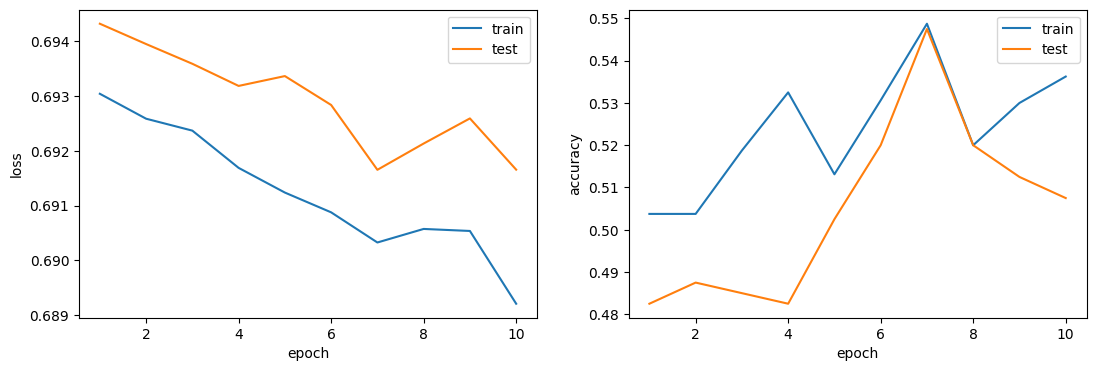

Epoch: 10, loss: 0.6916550993919373, accuracy: 0.5075


In [ ]:
NUM_EPOCH = 10
model_cnn = SimpleCNN(num_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0)

history = train(

    model_cnn, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH

)

In [ ]:
# Exp. 2. Better CNN model

In [ ]:
class BetterCNN(nn.Module):

    # Батчнорм -- это станлартизация по батчу (видимо, строкам),
    # лэернорм -- это стандартизация по фичам, а еще есть
    # некая инстанснорм
    # Нормализация тут нужна, чтобы грубо говоря для градиентного
    # спуска овалы превратить в круги для быстрого спуска: нормализуем,
    # смещаем куда надо (после линейного слоя), а потом подаем на функцию активации
    def __init__(self, batchnorm=False, dropout=0.0):
        super().__init__()

        # Вспомогательная функция для создания слоев блока
        # Эта функция автоматизирует создание повторяющихся блоков слоев,
        # чтобы не писать один и тот же код трижды.
        def block(in_channels, out_channels):

          # Сверточный слой. Использует ядро (фильтр) размера 3x3.
          # padding=1 (отступы по краям) гарантирует,
          # что сама операция свертки не уменьшает ширину и высоту картинки.
          # Изменяется только глубина — количество каналов
          #  (с in_channels до out_channels).
            layers = [
                nn.Conv2d(in_channels, out_channels, 3, padding=1),
            ]

            # Если при создании модели batchnorm=True,
            # после свертки добавляется нормализация.
            # Она стабилизирует и значительно ускоряет процесс обучения,
            # центрируя распределение признаков.
            if batchnorm:
                layers.append(nn.BatchNorm2d(out_channels))

            # nn.ReLU(): Функция активации (нелинейность).
            # Зануляет все отрицательные значения.
            # Без нелинейности вся нейросеть превратилась бы в одну большую сложную линейную регрессию.
            # nn.MaxPool2d(2): Слой субдискретизации (пулинг).
            # Выбирает максимальное значение из окошек 2x2.
            # Это уменьшает ширину и высоту изображения ровно в 2 раза,
            # помогая сети выделять более абстрактные и инвариантные к сдвигам признаки,
            # а также снижает затраты памяти.
            layers += [
                nn.ReLU(),
                nn.MaxPool2d(2),
            ]
            return layers

        # Основная часть извлечения признаков (Feature Extractor)
        # • nn.Sequential: Контейнер, который последовательно выполняет переданные в него слои.
        # • Синтаксис со звездочкой (*block(...)): Функция block возвращает список (list) слоев.
        # Звездочка «распаковывает» этот список, чтобы nn.Sequential получил слои по отдельности,
        # а не как вложенный список.
        # • Последовательность каналов: 3 -> 32 -> 64 -> 128.
        # На входе 3 канала (RGB-картинка). С каждым шагом сеть «всматривается» глубже,
        # увеличивая количество извлекаемых признаков (до 128),
        # пока разрешение самой картинки падает из-за MaxPool2d.
        # • nn.AdaptiveAvgPool2d(1): Очень важный слой.
        # Обычный пулинг уменьшает картинку в фиксированное число раз.
        # Адаптивный пулинг сжимает карту признаков до фиксированного размера 1x1,
        # независимо от того, какого размера картинка пришла на вход сети изначально.
        # На выходе из этого слоя мы получаем тензор размера [Batch_Size, 128, 1, 1].
        self.features = nn.Sequential(
            *block(3, 32),
            *block(32, 64),
            *block(64, 128),
            nn.AdaptiveAvgPool2d(1),
        )

        # Классификатор (Classifier)
        # • Признаки извлечены, теперь их нужно превратить в финальное предсказание (класс).
        # • nn.Flatten(): Сглаживает (вытягивает) многомерный тензор [Batch_Size, 128, 1, 1]
        # в плоский вектор [Batch_Size, 128]. Это необходимо перед подачей данных в полносвязный слой.
        # • nn.Dropout(dropout): Случайно зануляет часть связей во время обучения с заданной вероятностью.
        # Заставляет сеть не полагаться на отдельные «сильные» нейроны, что предотвращает переобучение
        #  (overfitting). Легенда про хинтона в банке.
        # • nn.Linear(128, 2): Финальный полносвязный слой.
        # Принимает 128 признаков и переводит их в 2 выхода
        #  (логиты для двух классов, например, "кошка" или "собака").
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128, 2),
        )

# • Метод forward определяет, как именно данные x (тензор с изображениями)
# проходят через модель при вызове model(images).
# • Данные сначала идут через блок извлечения признаков self.features,
# а затем результат передается в классификатор self.classifier, который возвращает итоговые предсказания.
    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1044, in _bootstrap_inner
    self.run()
    ~~~~~~~~^^
  File "/usr/lib/python3.13/threading.py", line 995, in run
    self._target(*self._args, **self._kwargs)
    ~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 289, in _feed
    queue_sem.release()
    ~~~~~~~~~~~~~~~~~^^
ValueError: semaphore or lock released too ma

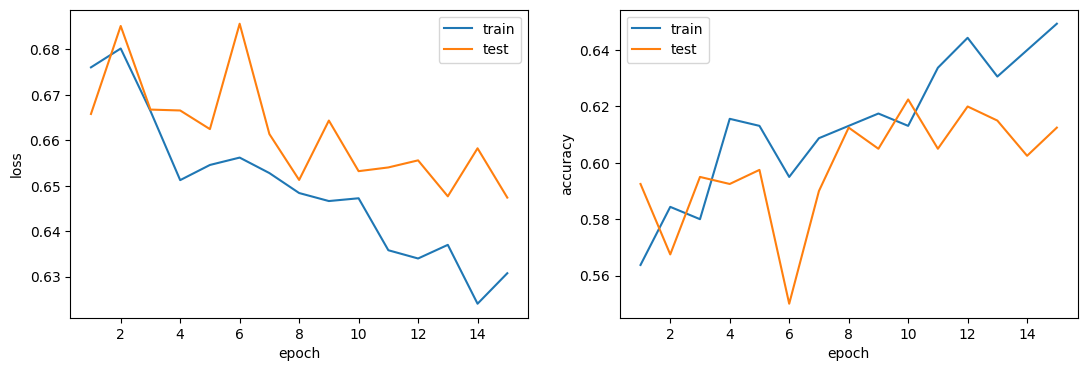

Epoch: 15, loss: 0.6474042534828186, accuracy: 0.6125


In [ ]:
NUM_EPOCH = 15
model_cnn = BetterCNN(batchnorm=3, dropout=0.3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0)

history = train(

    model_cnn, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH

)

In [22]:
#Exp 3. ResNet на выходе после слоя результат функции плюс то что было раньше (F(x) + x),
# что помогает фиксить ошибки

In [23]:
# Объявляем класс остаточного блока (Residual Block), наследуясь от базового класса модулей PyTorch
class ResidualBlock(nn.Module):
    # Конструктор принимает количество каналов (оно одинаковое для входа и выхода)
    def __init__(self, channels):
        super().__init__() # Инициализируем родительский класс nn.Module

        # Контейнер для последовательного выполнения основных слоев трансформации
        self.block = nn.Sequential(
            # Первая свертка: ядро 3х3, padding=1 сохраняет пространственный размер (H x W)
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            # Нормализация признаков по батчу для стабилизации обучения
            nn.BatchNorm2d(channels),
            # Функция активации ReLU (вводит нелинейность, зануляя отрицательные значения)
            nn.ReLU(),

            # Вторая свертка: аналогично сохраняет размеры и количество каналов
            nn.Conv2d(channels, channels, kernel_size=3, padding=1),
            # Вторая нормализация батча (активацию ReLU здесь внутри не вызываем)
            nn.BatchNorm2d(channels),
        )

        # Отдельная функция активации, которая применится уже ПОСЛЕ сложения
        self.relu = nn.ReLU()

    # Описываем прямой проход данных через блок
    def forward(self, x):
        # 1. Пропускаем входной тензор x через сверточные слои: self.block(x)
        # 2. Делаем skip connection (остаточное соединение): прибавляем исходный x к результату
        # 3. Применяем финальную активацию ReLU к полученной сумме
        return self.relu(x + self.block(x))


# Создаем класс нашей маленькой остаточной сети TinyResNet
class TinyResNet(nn.Module):
    def __init__(self):
        super().__init__() # Инициализируем базовый класс nn.Module

        # Объединяем все слои в один последовательный контейнер nn.Sequential
        self.model = nn.Sequential(
            # --- ВХОДНОЙ БЛОК (ПРИЕМ КАРТИНКИ) ---
            # Принимает 3 RGB-канала, выдает 32 канала. Ядро 3х3, padding=1 сохраняет размер.
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            # Нормализуем 32 канала для стабильного старта обучения
            nn.BatchNorm2d(32),
            # Функция нелинейности ReLU
            nn.ReLU(),
            # Уменьшаем высоту и ширину картинки в 2 раза (например, со 128x128 до 64x64)
            nn.MaxPool2d(kernel_size=2),

            # --- СТРУКТУРНЫЙ БЛОК 1 (32 КАНАЛА) ---
            # Обрабатывает признаки на текущем разрешении. Каналы (32) и размеры не меняются.
            ResidualBlock(32),

            # --- ПЕРЕХОД НА 64 КАНАЛА ---
            # Увеличиваем каналы с 32 до 64. Параметр stride=2 уменьшает высоту/ширину картинки в 2 раза.
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            # --- СТРУКТУРНЫЙ БЛОК 2 (64 КАНАЛА) ---
            # Наш остаточный блок обрабатывает уже 64 канала, сохраняя стабильность градиентов.
            ResidualBlock(64),

            # --- ПЕРЕХОД НА 128 КАНАЛОВ ---
            # Снова увеличиваем глубину (каналы с 64 до 128) и сжимаем картинку в 2 раза через stride=2.
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            # --- СТРУКТУРНЫЙ БЛОК 3 (128 КАНАЛОВ) ---
            # Финальный остаточный блок для обработки самых глубоких и абстрактных признаков.
            ResidualBlock(128),

            # --- ВЫХОДНОЙ БЛОК (КЛАССИФИКАТОР) ---
            # Сжимает высоту и ширину признаков до 1х1, превращая тензор в размер [Batch, 128, 1, 1]
            nn.AdaptiveAvgPool2d(1),
            # Вытягивает многомерные карты признаков в плоский вектор [Batch, 128]
            nn.Flatten(),
            # Финальный полносвязный слой. Берет 128 признаков и выдает 2 логита (для 2 классов предсказания)
            nn.Linear(128, 2),
        )

    # Метод прямого прохода
    def forward(self, x):
        # Просто передаем входные изображения x через всю цепочку слоев self.model
        return self.model(x)

In [24]:
# В оптимизаторе torch.optim.SGD параметр momentum (моментум / импульс) — это техника,
# которая ускоряет градиентный спуск, помогая модели быстрее обучаться, избегать застревания в локальных минимумах и сглаживать сильные колебания (осцилляции) градиента.
# # Если говорить простыми словами: обычный градиентный спуск делает шаг только на основе текущего градиента.
# Градиентный спуск с моментумом ведет себя как тяжелый шарик, катящийся
# с холма: он «накапливает скорость» за счет предыдущих шагов и за счет этой инерции может проскочить
# небольшие кочки (локальные минимумы) или плоские участки.
# Это та самая инерция h.
# Оптимайзер -- алгоритм обновления весов.

Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor
Exception in thread QueueFeederThread:
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/queues.py", line 257, in _feed
    reader_close()
    ~~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 183, in close
    self._close()
    ~~~~~~~~~~~^^
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
    ~~~~~~^^^^^^^^^^^^^^
OSError: [Errno 9] Bad file descriptor

During handling of the above exception, another exception occurred:

Traceback (most recent call

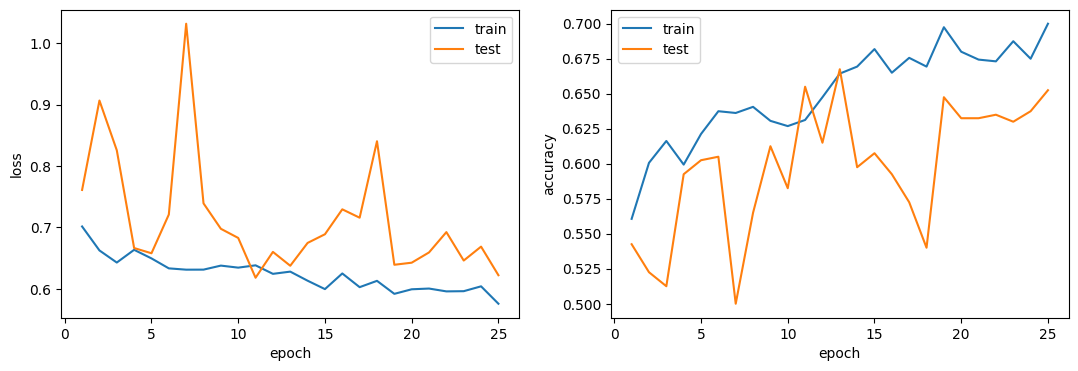

Epoch: 25, loss: 0.6222336292266846, accuracy: 0.6525


In [25]:
NUM_EPOCH = 25

model_rn = TinyResNet().to(device)
criterion = nn.CrossEntropyLoss()
# в лекции моментум 0.9, в прошлом файле ставил 0.1
optimizer = torch.optim.SGD(model_rn.parameters(), lr=0.01, momentum=0.9)

history = train(

    model_rn, optimizer, criterion,
    train_loader, val_loader,
    NUM_EPOCH

)